# 04 · Approach-risk model

**Task:** given a tropical cyclone's state *right now*, when it is 150-600 nm from Jamaica, estimate the probability that it will pass within 100 nm of the coast in the next 72 hours.

This isn't a replacement for NHC forecasts, which use full numerical weather models. The question is how much skill a lightweight, transparent model trained on 75 years of best tracks can add over the naive **persistence** forecast ("keep going in a straight line at the current speed"). A model like that is cheap enough to run inside a dashboard or an early-warning trigger for a business.

**Leakage guard:** the 6-hourly rows of one storm are highly correlated, so every split is **grouped by storm**. I also report a strict **time-based holdout** (train 1950-2014, test 2015-2025).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jhurricane import config, plotting as P

P.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

storms = pd.read_csv(config.DATA_PROCESSED / "storms.csv", parse_dates=["closest_datetime"])
seasons = pd.read_csv(config.DATA_PROCESSED / "seasons.csv")
points = pd.read_csv(config.DATA_PROCESSED / "track_points.csv", parse_dates=["datetime"])
impacts = pd.read_csv(config.DATA_PROCESSED / "impacts.csv")
near = storms[storms["is_near"]].copy()

In [2]:
from jhurricane import hurdat, features, model

fixes = hurdat.parse()
oni = features.load_oni()
data = model.build_dataset(fixes, oni)
print(f"{len(data):,} storm-states from {data['storm_id'].nunique()} storms, 1950-2025")
print(f"Positive rate (passes within 100 nm in next 72 h): {data['label'].mean():.1%}")
data[model.FEATURES + ["label"]].describe().T[["mean", "std", "min", "max"]].round(2)

4,217 storm-states from 429 storms, 1950-2025
Positive rate (passes within 100 nm in next 72 h): 5.0%


,mean,std,min,max
dist_nm,413.46,121.71,150.04,599.93
rel_lat,2.30,4.61,-9.51,10.39
rel_lon,-1.13,6.26,-11.60,11.50
bearing_sin,-0.15,0.74,-1.00,1.00
bearing_cos,0.27,0.60,-1.00,1.00
heading_sin,-0.44,0.61,-1.00,1.00
heading_cos,0.45,0.48,-1.00,1.00
speed_kt,9.10,4.62,0.00,34.24
closing_speed_kt,-1.24,7.13,-21.84,28.80
wind_kt,56.02,30.22,15.00,165.00


In [3]:
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y, groups = data[model.FEATURES], data["label"].values, data["storm_id"].values

def make_models():
    return {
        "Persistence (straight-line)": make_pipeline(StandardScaler(), LogisticRegression()),
        "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)),
        "Gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                                            l2_regularization=1.0, random_state=42),
    }

def cols_for(name):
    return ["persistence_min_dist_nm"] if name.startswith("Persistence") else model.FEATURES

oof = {name: np.zeros(len(data)) for name in make_models()}
for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups):
    for name, est in make_models().items():
        c = cols_for(name)
        est.fit(X.iloc[train_idx][c], y[train_idx])
        oof[name][test_idx] = est.predict_proba(X.iloc[test_idx][c])[:, 1]

def scores(y_true, p):
    return {"ROC AUC": roc_auc_score(y_true, p), "Avg precision": average_precision_score(y_true, p),
            "Brier": brier_score_loss(y_true, p)}

cv = pd.DataFrame({name: scores(y, p) for name, p in oof.items()}).T
cv["Avg precision lift vs base rate"] = cv["Avg precision"] / y.mean()
cv.round(3)

,ROC AUC,Avg precision,Brier,Avg precision lift vs base rate
Persistence (straight-line),0.948,0.478,0.031,9.547
Logistic regression,0.958,0.593,0.029,11.854
Gradient boosting,0.929,0.503,0.033,10.046


In [4]:
train = data["year"] < 2015
test = ~train
holdout = {}
fitted = {}
for name, est in make_models().items():
    c = cols_for(name)
    est.fit(X.loc[train, c], y[train])
    fitted[name] = est
    holdout[name] = scores(y[test], est.predict_proba(X.loc[test, c])[:, 1])
print(f"Holdout: {test.sum()} storm-states from {data.loc[test, 'storm_id'].nunique()} storms (2015-2025), "
      f"{y[test].sum()} positives")
pd.DataFrame(holdout).T.round(3)

Holdout: 617 storm-states from 65 storms (2015-2025), 24 positives


,ROC AUC,Avg precision,Brier
Persistence (straight-line),0.978,0.571,0.022
Logistic regression,0.982,0.644,0.023
Gradient boosting,0.980,0.605,0.023


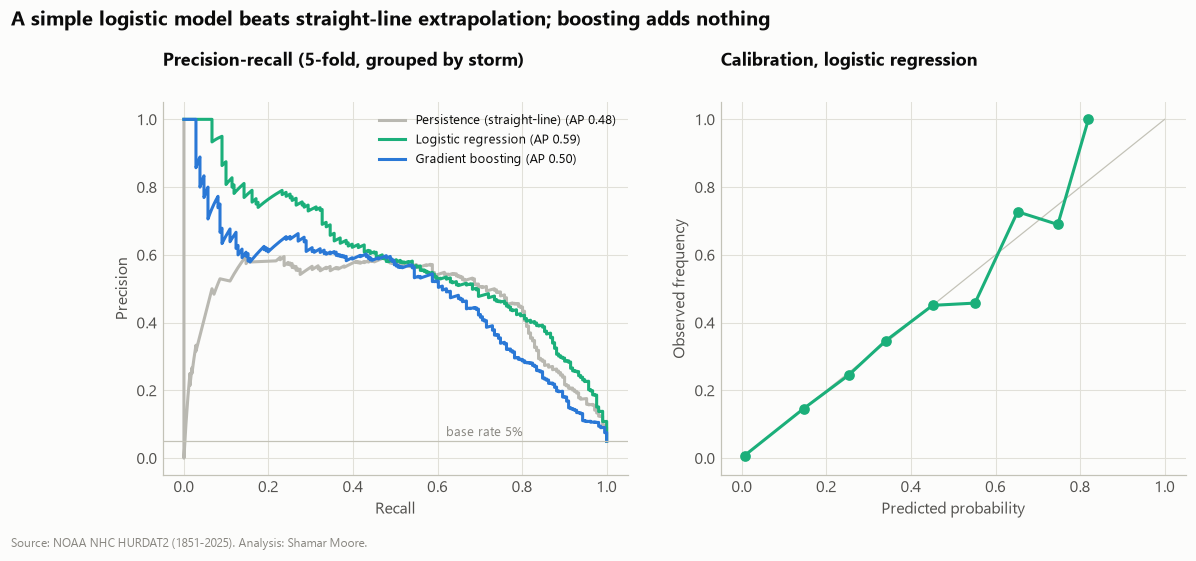

In [5]:
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
palette = {"Persistence (straight-line)": P.GRAY, "Logistic regression": P.AQUA, "Gradient boosting": P.BLUE}
for name, p in oof.items():
    prec, rec, _ = precision_recall_curve(y, p)
    axes[0].plot(rec, prec, color=palette[name], lw=2, label=f"{name} (AP {average_precision_score(y, p):.2f})")
axes[0].axhline(y.mean(), color=P.AXIS, lw=0.8)
axes[0].text(0.62, y.mean() + 0.015, f"base rate {y.mean():.0%}", fontsize=8.5, color=P.MUTED)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(fontsize=8.5, loc="upper right")
axes[0].set_title("Precision-recall (5-fold, grouped by storm)", fontsize=11.5)

frac, mean_pred = calibration_curve(y, oof["Logistic regression"], n_bins=10, strategy="uniform")
axes[1].plot([0, 1], [0, 1], color=P.AXIS, lw=0.8)
axes[1].plot(mean_pred, frac, color=P.AQUA, marker="o", ms=6, lw=2)
axes[1].set_xlabel("Predicted probability")
axes[1].set_ylabel("Observed frequency")
axes[1].set_title("Calibration, logistic regression", fontsize=11.5)
fig.suptitle("A simple logistic model beats straight-line extrapolation; boosting adds nothing", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.07)
P.source_note(fig)
fig.savefig(config.FIGURES / "04_model_performance.png")
plt.show()

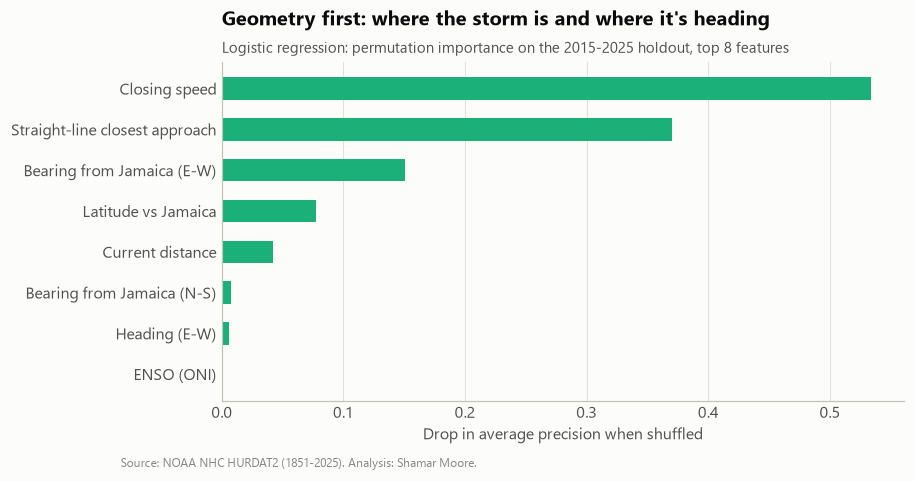

In [6]:
from sklearn.inspection import permutation_importance

lr = fitted["Logistic regression"]
imp = permutation_importance(lr, X.loc[test, model.FEATURES], y[test], scoring="average_precision",
                             n_repeats=30, random_state=0)
fi = pd.Series(imp.importances_mean, index=model.FEATURES).sort_values()
nice = {"persistence_min_dist_nm": "Straight-line closest approach", "dist_nm": "Current distance",
        "closing_speed_kt": "Closing speed", "rel_lat": "Latitude vs Jamaica", "rel_lon": "Longitude vs Jamaica",
        "bearing_sin": "Bearing from Jamaica (E-W)", "bearing_cos": "Bearing from Jamaica (N-S)",
        "heading_sin": "Heading (E-W)", "heading_cos": "Heading (N-S)", "speed_kt": "Forward speed",
        "wind_kt": "Intensity", "wind_change_24h": "24 h intensity change", "month": "Month", "oni": "ENSO (ONI)"}
top = fi.tail(8)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([nice[i] for i in top.index], top.values, color=P.AQUA, height=0.55)
ax.set_xlabel("Drop in average precision when shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("Geometry first: where the storm is and where it's heading")
P.subtitle(ax, "Logistic regression: permutation importance on the 2015-2025 holdout, top 8 features")
P.source_note(fig)
fig.savefig(config.FIGURES / "04_feature_importance.png")
plt.show()

## Case studies: Beryl (2024) and Melissa (2025)

These are out-of-sample: both storms are in the 2015-2025 holdout, so the model never saw them in training.

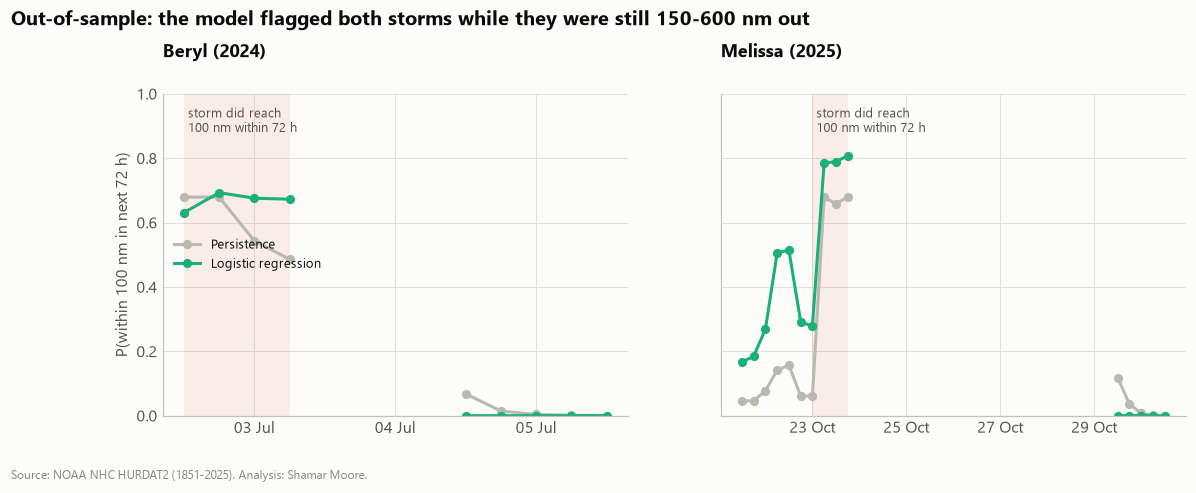

In [7]:
import matplotlib.dates as mdates
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, name, year in [(axes[0], "BERYL", 2024), (axes[1], "MELISSA", 2025)]:
    d = data[(data["storm_name"] == name) & (data["year"] == year)].copy()
    d["p_lr"] = lr.predict_proba(d[model.FEATURES])[:, 1]
    d["p_pers"] = fitted["Persistence (straight-line)"].predict_proba(d[["persistence_min_dist_nm"]])[:, 1]
    # Break the lines where the storm left the 150-600 nm band, so gaps aren't drawn as trends.
    breaks = d[d["datetime"].diff() > pd.Timedelta(hours=12)].assign(p_lr=np.nan, p_pers=np.nan)
    breaks["datetime"] -= pd.Timedelta(hours=1)
    d = pd.concat([d, breaks]).sort_values("datetime")
    ax.plot(d["datetime"], d["p_pers"], color=P.GRAY, lw=2, marker="o", ms=5, label="Persistence")
    ax.plot(d["datetime"], d["p_lr"], color=P.AQUA, lw=2, marker="o", ms=5, label="Logistic regression")
    hits = d[d["label"] == 1]
    if len(hits):
        ax.axvspan(hits["datetime"].min(), hits["datetime"].max(), color=P.ORANGE, alpha=0.10, lw=0)
        ax.text(hits["datetime"].min(), 0.96, " storm did reach\n 100 nm within 72 h", fontsize=8.5, color=P.INK_2, va="top")
    ax.set_title(f"{name.title()} ({year})", fontsize=11.5)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1 if name == "BERYL" else 2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].set_ylabel("P(within 100 nm in next 72 h)")
axes[0].legend(fontsize=8.5, loc="center left")
fig.suptitle("Out-of-sample: the model flagged both storms while they were still 150-600 nm out", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.08)
P.source_note(fig)
fig.savefig(config.FIGURES / "04_case_studies.png")
plt.show()

### Takeaways and limitations

* Using only a storm's current state, a **regularised logistic regression beats straight-line persistence** on average precision: 0.59 vs 0.48 in grouped cross-validation, and 0.64 vs 0.57 on the 2015-2025 holdout.
* **Gradient boosting didn't help.** With ~4,200 rows from only ~430 storms (and ~200 positives), the extra flexibility overfits. The simpler, more explainable model is the one I'd ship.
* Most of the signal is **geometric** (position, heading, closing speed). ENSO and intensity add a little.
* **Limitations:** no steering-flow or model-guidance inputs, so it can't anticipate recurvature the way NHC can. Labels come from final best tracks, not real-time operational data. Positives are rare (~5%), so the confidence intervals on these metrics are wide. Treat it as a screening tool, not a forecast.